### Install necessary libraries ###

In [37]:
%pip install "datasets[audio]" librosa jiwer matplotlib transformers torch torchaudio

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [38]:
import torch
import librosa
import jiwer
import transformers
from datasets import load_dataset
from transformers import pipeline
import sys
import torch
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Audio, display

print("Python environment:", __import__("sys").executable)
print("CUDA available:", torch.cuda.is_available())
print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("TorchCodec:", metadata.version("torchcodec"))
print("Datasets:", metadata.version("datasets"))
print("All imports successful!")

Python environment: c:\Users\ashle\code-switching\.venv\Scripts\python.exe
CUDA available: False
Python: c:\Users\ashle\code-switching\.venv\Scripts\python.exe
PyTorch: 2.15.0+cpu
TorchCodec: 0.17.0
Datasets: 5.1.0
All imports successful!


In [39]:
device = 0 if torch.cuda.is_available() else -1

def get_transcriber(model_name="openai/whisper-tiny"):
    return pipeline(
        "automatic-speech-recognition",
        model=model_name,
        device=device,
    )

transcriber = get_transcriber("openai/whisper-tiny")
print("Whisper is ready!")

Loading weights: 100%|██████████| 167/167 [00:00<00:00, 435.72it/s]


Whisper is ready!


In [40]:
# 100% english dataset

# dataset = load_dataset(
#     "PolyAI/minds14",
#     name="en-AU",
#     split="train"
# )

# Load a small subset of spanish-english code-switching dataset for testing

dataset = load_dataset(
    "ky552/cszs_es_en",
    split="train[:100]"
)

sample = dataset[0]
print(sample.keys())

dict_keys(['correct_audio', 'correct_transcription', 'correct_file', 'wrong_audio', 'wrong_transcription', 'wrong_file'])


In [41]:
audio = sample["correct_audio"]

result = transcriber({
    "raw": audio["array"],
    "sampling_rate": audio["sampling_rate"]
})

print("Reference:", sample["correct_transcription"])
print("Prediction:", result["text"])

Reference: Algunas armas use two tipos de munición.
Prediction:  algunas armas y ustutipos de munición.


In [42]:
def print_sample_transcriptions(dataset, num_samples=5):
    for i in range(num_samples):
        example = dataset[i]
        print(f"Example {i}")
        print("Correct transcription:", example["correct_transcription"])
        print("Wrong transcription:", example["wrong_transcription"])
        print("-" * 50)

In [43]:
print_sample_transcriptions(dataset, num_samples=5)

Example 0
Correct transcription: Algunas armas use two tipos de munición.
Wrong transcription: Algunas armas use tres tipos de munición.
--------------------------------------------------
Example 1
Correct transcription: Desde el principio, the proyecto estuvo plagued por la falta de experiencia en engineering.
Wrong transcription: Desde el principio, the proyecto estuvo plagued por la falta de experiencia en swimming.
--------------------------------------------------
Example 2
Correct transcription: El disco includes catorce tracks.
Wrong transcription: El includes catorce disco tracks.
--------------------------------------------------
Example 3
Correct transcription: Part of the directorio of the Sociedad Rural Argentina formó.
Wrong transcription: Part of the orange of the Sociedad Rural Argentina formó.
--------------------------------------------------
Example 4
Correct transcription: Situado en la provincia de Castellón, in the region of la Plana Alta.
Wrong transcription: Situ

In [44]:
def print_audio_durations(dataset):
    durations = []
    for i in range(len(dataset)):
        audio = dataset[i]["correct_audio"]
        duration = len(audio["array"]) / audio["sampling_rate"]
        durations.append(duration)
    print(f"Shortest clip: {min(durations):.2f} seconds")
    print(f"Longest clip: {max(durations):.2f} seconds")
    print(f"Average duration: {np.mean(durations):.2f} seconds")

In [45]:
print_audio_durations(dataset)

Shortest clip: 1.72 seconds
Longest clip: 6.35 seconds
Average duration: 3.82 seconds


In [ ]:
num_samples = min(50, len(dataset))

results = []

for i in range(num_samples):

    sample = dataset[i]
    audio = sample["correct_audio"]

    prediction = transcriber({
        "raw": audio["array"],
        "sampling_rate": audio["sampling_rate"]
    })

    results.append({
        "id": i,
        "actual": sample["correct_transcription"],
        "predicted": prediction["text"]
    })

df = pd.DataFrame(results)


In [ ]:
from jiwer import wer

df["wer"] = [
    wer(actual, predicted)
    for actual, predicted in zip(
        df["actual"],
        df["predicted"]
    )
]

df.sort_values(by="wer", ascending=True, inplace=True)

display(df[["id", "actual", "predicted", "wer"]])

print("Average WER:", df["wer"].mean())


C:\Users\ashle\AppData\Local\Temp\ipykernel_33836\3768883996.py:11: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.sort_values(by="wer", ascending=True, inplace=True)


,id,actual,predicted,wer
38,38,"A partir de ese moment, los sucesos discográfi...","A partir de ese momento, los sucesos discográ...",0.090909
17,17,Se puede considerar que he's el precursor mito...,se puede considerar que giza el precursor mit...,0.200000
34,34,"Al tener both parents Mexicanos, Gilbert posse...","Al tener both parents mexicanos, Gilbert pose...",0.250000
1,1,"Desde el principio, the proyecto estuvo plague...","Desde el principio, de proyecto estuvo play p...",0.285714
32,32,Todos los sectores of the economy se desarroll...,Todos los sectores ofde y con homice desarrol...,0.357143
45,45,"Es un recurso simple, so narcisista como super...","Es un recurso simple, son ejercistas como sup...",0.375000
40,40,Que lo colocan in a crossroads respecto de sus...,que lo colocan y nacró lo respecto de sus con...,0.400000
8,8,Even he offered concerts en ciudades españolas.,y gengí ofert concerts en ciudades españolas.,0.428571
42,42,"Para Vallejo, every true love es doliente.","Para Vallejo, Evry Trullofe es doliente.",0.428571
37,37,La canción sigue siendo un basic tema of The A...,La canción sigue siendo un besic tema de alma...,0.454545


Average WER: 0.6230090465090465


In [ ]:
# Listen to the 5 best and 5 worst predictions

selected_predictions = pd.concat([
    df.head(5).assign(category="Best"),
    df.tail(5).assign(category="Worst"),
])

for prediction in selected_predictions.itertuples(index=False):
    sample = dataset[int(prediction.id)]
    audio = sample["correct_audio"]

    print(f"{prediction.category} prediction - sample {prediction.id}")
    display(Audio(audio["array"], rate=audio["sampling_rate"]))
    print("Actual:", prediction.actual)
    print("Prediction:", prediction.predicted)
    print("WER:", f"{prediction.wer:.3f}")
    print()

Best prediction - sample 38


Actual: A partir de ese moment, los sucesos discográficos no se stop.
Prediction:  A partir de ese momento, los sucesos discográficos no se stop.
WER: 0.091

Best prediction - sample 17


Actual: Se puede considerar que he's el precursor mitológico del robot.
Prediction:  se puede considerar que giza el precursor mitológico del robot.
WER: 0.200

Best prediction - sample 34


Actual: Al tener both parents Mexicanos, Gilbert possesses doble nacionalidad, and mexican ancestry.
Prediction:  Al tener both parents mexicanos, Gilbert poseses doble nacionalidad, an mexican ancestry.
WER: 0.250

Best prediction - sample 1


Actual: Desde el principio, the proyecto estuvo plagued por la falta de experiencia en engineering.
Prediction:  Desde el principio, de proyecto estuvo play por la falta de experiencia en el niñering.
WER: 0.286

Best prediction - sample 32


Actual: Todos los sectores of the economy se desarrollaron ya que el frente civil prospered.
Prediction:  Todos los sectores ofde y con homice desarrollaron ya que el frente civil prosperta.
WER: 0.357

Worst prediction - sample 29


Actual: Las hojas se agrupan in heads around the tallo of la planta.
Prediction:  La soja se agrupa en ingercer a un detalle o flasplanta.
WER: 0.917

Worst prediction - sample 12


Actual: Este disco has songs like: Cielo azul, cielo nublado and Ungrateful love.
Prediction:  Este disco has son like, se lo ha azul, se lo ha unublado andangrate full of.
WER: 1.000

Worst prediction - sample 19


Actual: Finally he finished his career with the Natal Sharks.
Prediction:  Φαίνα λιχή φυνιστχή σκαιρίροι δεν έει τα αρσάρξη.
WER: 1.000

Worst prediction - sample 25


Actual: Jaime de Salazar y Acha adopts a postura que mantiene both teorías.
Prediction:  Χαίμαι δεσαλαφαριακσα δοτσσα πωστούρα και μαντήνε ο Βουυτεορίας.
WER: 1.000

Worst prediction - sample 47


Actual: Se divide en seven parroquias.
Prediction:  Se diva y ven se ven parroquias.
WER: 1.000



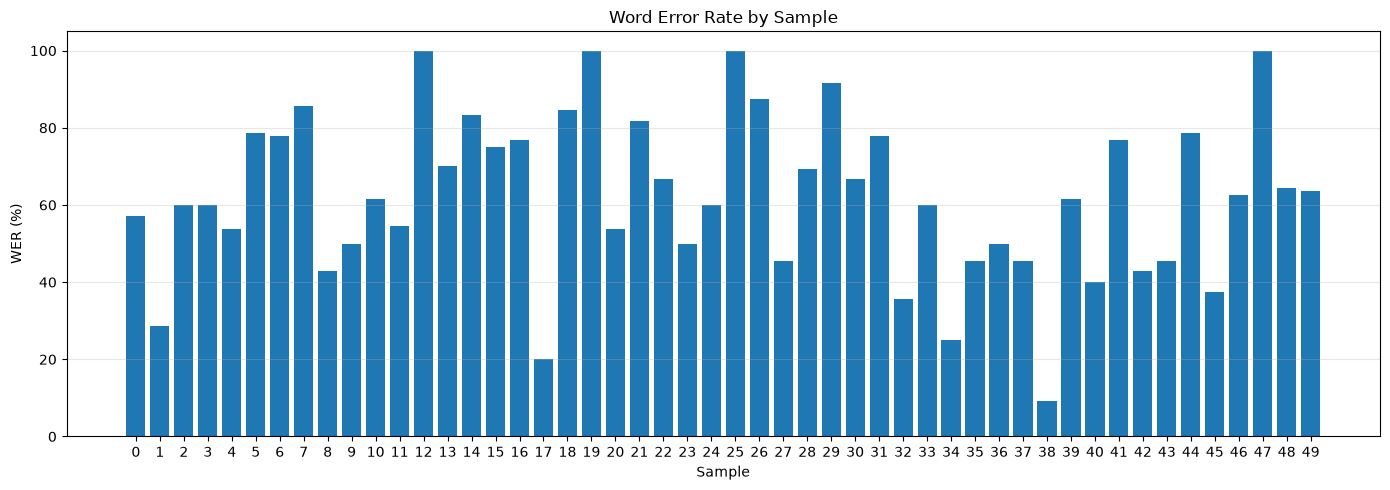

In [ ]:
plot_df = df.sort_values("id")

plt.figure(figsize=(14, 5))
plt.bar(plot_df["id"], plot_df["wer"] * 100)
plt.xlabel("Sample")
plt.ylabel("WER (%)")
plt.title("Word Error Rate by Sample")
plt.xticks(plot_df["id"])
plt.ylim(bottom=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
error_analysis_df = (
    df.sort_values("wer", ascending=False)
    .head(20)
    [["id", "actual", "predicted", "wer"]]
    .reset_index(drop=True)
)
error_analysis_df["error_explanation"] = ""

display(
    error_analysis_df.style.format({"wer": "{:.3f}"})
)

,id,actual,predicted,wer,error_explanation
0,25,Jaime de Salazar y Acha adopts a postura que mantiene both teorías.,Χαίμαι δεσαλαφαριακσα δοτσσα πωστούρα και μαντήνε ο Βουυτεορίας.,1.000,
1,47,Se divide en seven parroquias.,Se diva y ven se ven parroquias.,1.000,
2,12,"Este disco has songs like: Cielo azul, cielo nublado and Ungrateful love.","Este disco has son like, se lo ha azul, se lo ha unublado andangrate full of.",1.000,
3,19,Finally he finished his career with the Natal Sharks.,Φαίνα λιχή φυνιστχή σκαιρίροι δεν έει τα αρσάρξη.,1.000,
4,29,Las hojas se agrupan in heads around the tallo of la planta.,La soja se agrupa en ingercer a un detalle o flasplanta.,0.917,
5,26,Is his first international lanzamiento outside of Europe.,Esquisirse de internas en el lanzamiento Alzheimer Europe.,0.875,
6,7,The origen of the image es desconocido.,de origenos de emiches desconocido.,0.857,
7,18,"They feed on una amplia gama of fishes, crustaceans —especially shrimps— and cefalópodos.","Del fido en una amplia gama ofices, trusteisan si especial y ríns, antefaló podos.",0.846,
8,14,"During the Fase de Clasificación, we will observe the Sistema de Puntos.","Durin de fase de clasificación, UIWILOBSERF de sistema de puntos.",0.833,
9,21,Clemente de Alexandria and Origen became the founders of Christian philosophy.,Climente de Alexandria andorigen bicainde faun del sofristan filosofía.,0.818,
